# Group Members
### 1. Md Ahsan Habib Sadik (2210976101)
### 5. Md. Murad (2210370102)
### 4. Most. Faria Jabin Khanam (2212576117)
### 2. Soumithra Debnath Shanto (2210976136)
### 3. Mahfuzur Rahman (2110976149)

In [1]:
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
from keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

I0000 00:00:1787398397.129079  117450 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787398397.161725  117450 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787398398.049984  117450 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
DATA_DIR = 'dataset'
BATCH_SIZE = 128
IMG_SIZE = (256, 256)
EPOCHS = 100

In [3]:
# Split Dataset (70% Train, 15% Val, 15% Test)

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3, # Reserves 30% for val + test combined
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Load the remaining 30% (Validation + Test combined)
val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 4948 files belonging to 2 classes.
Using 3464 files for training.


W0000 00:00:1787398399.229508  117450 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1787398399.234542  117450 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1787398399.317086  117450 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13713 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a
E0000 00:00:1787398399.566725  117560 ptx_compiler_helpers.cc:154] *** WARNING *** Invoking ptxas with version 12.3.52, which corresponds to a CUDA version <=12.6.2. CUDA versions 12.x.y up to and including 12.6.2 miscompile certain edge cases around clamping.
Please upgrade to CUDA 12.6.3 

Found 4948 files belonging to 2 classes.
Using 1484 files for validation.


In [4]:
# Divide the 30% split equally into Validation (15%) and Test (15%)

total_val_test_batches = len(val_test_dataset)
val_size = total_val_test_batches // 2

val_dataset = val_test_dataset.take(val_size)
test_dataset = val_test_dataset.skip(val_size)

print(f"\nBatch allocations:")
print(f"Training batches: {len(train_dataset)} (~3,360 images)")
print(f"Validation batches: {len(val_dataset)} (~720 images)")
print(f"Test batches: {len(test_dataset)} (~720 images)")


Batch allocations:
Training batches: 28 (~3,360 images)
Validation batches: 6 (~720 images)
Test batches: 6 (~720 images)


In [5]:
# 3. Optimize Dataset for Performance
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

In [6]:
# Build the CNN Model Architecture

model = models.Sequential([
    tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    
    # Data Augmentation & Normalization
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.Rescaling(1./255),
    
    # Convolutional Layers
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(512, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    
    # Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(2, activation='softmax')
])

W0000 00:00:1787398400.323433  117618 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.324629  117621 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.325569  117624 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.326918  117625 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.327862  117623 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.329659  117617 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398400.330694  117627 gpu_kernel_to_blob_pass.cc:190] Failed to co

In [7]:
# Compile and Train
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,930,098 (14.99 MB)

 Trainable params: 3,930,098 (14.99 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
print("\nStarting Training...")
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Starting Training...
Epoch 1/100


/home/sadik/miniconda3/envs/vision/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1787398402.078712  117677 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398402.079721  117684 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398402.083699  117687 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398402.084602  117678 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787398402.085693  117685

28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 158ms/step - accuracy: 0.5084 - loss: 0.6950 - val_accuracy: 0.5026 - val_loss: 0.6931
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.4997 - loss: 0.6932 - val_accuracy: 0.5560 - val_loss: 0.6930
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - accuracy: 0.5430 - loss: 0.6866 - val_accuracy: 0.5964 - val_loss: 0.6657
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.5684 - loss: 0.6635 - val_accuracy: 0.5651 - val_loss: 0.6539
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.5644 - loss: 0.6689 - val_accuracy: 0.5169 - val_loss: 0.6863
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.5632 - loss: 0.6653 - val_accuracy: 0.5872 - val_loss: 0.6489
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - accuracy: 0.5872 - loss: 0.6497 - val_accuracy: 0.6081 - val_loss: 0.6306
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - accuracy: 0.6120 - loss: 0.6380 - val_accuracy: 0.502

In [10]:
# Final Evaluation on Unseen Test Dataset
print("\nEvaluating model on the held-out Test Dataset...")
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f" Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f" Final Test Loss:     {test_loss:.4f}")


Evaluating model on the held-out Test Dataset...
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - accuracy: 0.9372 - loss: 0.2268
 Final Test Accuracy: 93.72%
 Final Test Loss:     0.2268


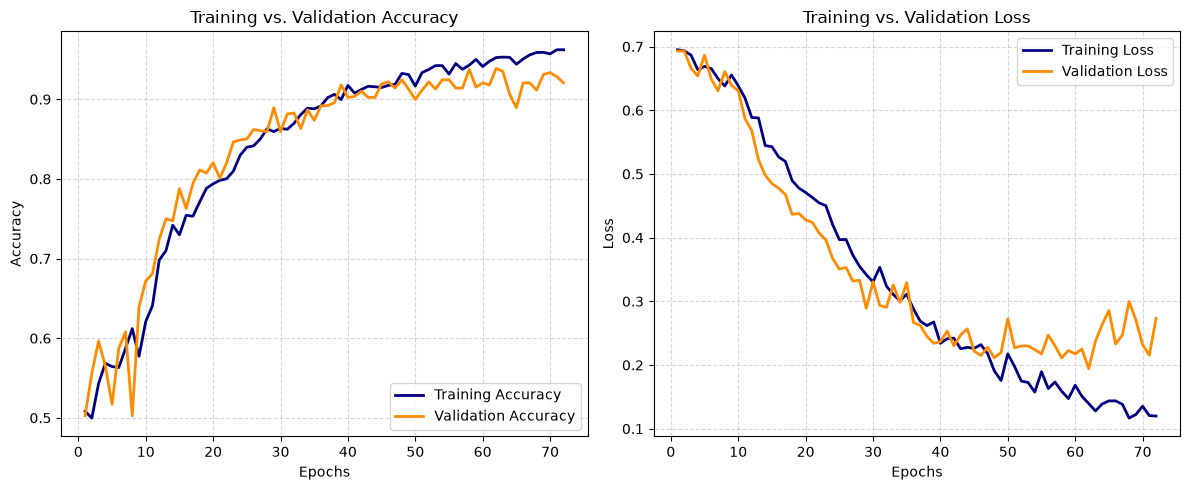

In [11]:
import matplotlib.pyplot as plt

# Extract metrics from model history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='navy', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='darkorange', linewidth=2)
plt.title('Training vs. Validation Accuracy', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='navy', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='darkorange', linewidth=2)
plt.title('Training vs. Validation Loss', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
# Save Model
model.save("leaf_classifier_model.keras")
print("\nModel saved as 'leaf_classifier_model.keras'")


Model saved as 'leaf_classifier_model.keras'


In [13]:
# Define class names 
class_names = ['aam_pata', 'kathal_pata']

In [14]:
# Collect Predictions & True Labels

y_true = []
y_pred = []

# Iterate over test_dataset batches to keep labels and predictions aligned
for images, labels in test_dataset:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)


================ Classification Report ================
              precision    recall  f1-score   support

    aam_pata     0.9413    0.9335    0.9374       361
 kathal_pata     0.9330    0.9408    0.9369       355

    accuracy                         0.9372       716
   macro avg     0.9372    0.9372    0.9371       716
weighted avg     0.9372    0.9372    0.9372       716




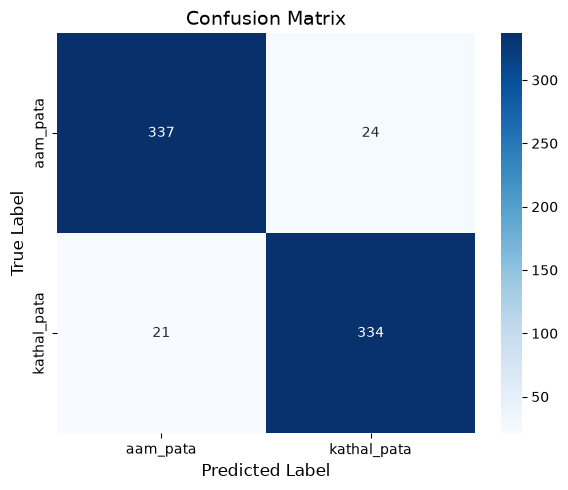

In [15]:
# Generate Classification Report

print("\n================ Classification Report ================")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("\n====================================================")

# 3. Compute & Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=class_names, 
    yticklabels=class_names
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.tight_layout()
plt.show()